## Aim

To develop a Python-based employee management system using PostgreSQL and perform basic CRUD operations on employee, department, and role data.

## Procedure

1. Installed and configured PostgreSQL in Google Colab.
2. Created the `employee_db` database.
3. Created `employees`, `departments`, and `roles` tables.
4. Inserted department, role, and employee records.
5. Performed Create, Read, Update, and Delete (CRUD) operations.
6. Used SQL JOIN to retrieve related employee data.
7. Used Pandas to display and analyze the data.
8. Created bar charts for salary and department-wise employee distribution.

In [ ]:
!apt-get update -qq
!apt-get install -y postgresql postgresql-contrib -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
Selecting previously unselected package logrotate.
(Reading database ... 118419 files and directories currently installed.)
Preparing to unpack .../00-logrotate_3.19.0-1ubuntu1.1_amd64.deb ...
Unpacking logrotate (3.19.0-1ubuntu1.1) ...
Selecting previously unselected package netbase.
Preparing to unpack .../01-netbase_6.3_all.deb ...
Unpacking netbase (6.3) ...
Selecting previously unselected package libcommon-sense-perl:amd64.
Preparing to unpack .../02-libcommon-sense-perl_3.75-2build1_amd64.deb ...
Unpacking libcommon-sense-perl:amd64 (3.75-2build1) ...
Selecting previously unselected package libjson-perl.
Preparing to unpack .../03-libjson-perl_4.04000-1_all.deb ...
Unpacking libjson-perl (4.04000-1) ...
Selecting previously unselected package libtypes-serialiser-perl

In [ ]:
!service postgresql start

 * Starting PostgreSQL 14 database server
   ...done.


In [ ]:
!pip install psycopg2-binary -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 22.8 MB/s eta 0:00:00


In [ ]:
!sudo -u postgres psql -c "CREATE DATABASE employee_db;"

CREATE DATABASE


In [ ]:
!sudo -u postgres psql -c "ALTER USER postgres PASSWORD 'postgres';"

ALTER ROLE


In [ ]:
import psycopg2

conn = psycopg2.connect(
    host="localhost",
    database="employee_db",
    user="postgres",
    password="postgres"
)

cursor = conn.cursor()

print("Connected to PostgreSQL successfully!")

Connected to PostgreSQL successfully!


In [ ]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS departments (
    department_id SERIAL PRIMARY KEY,
    department_name VARCHAR(100) NOT NULL
);
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS roles (
    role_id SERIAL PRIMARY KEY,
    role_name VARCHAR(100) NOT NULL
);
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS employees (
    employee_id SERIAL PRIMARY KEY,
    employee_name VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    salary DECIMAL(10,2),
    department_id INT REFERENCES departments(department_id),
    role_id INT REFERENCES roles(role_id)
);
""")

conn.commit()

print("Tables created successfully!")

Tables created successfully!


In [ ]:
departments = [
    ("IT",),
    ("HR",),
    ("Finance",),
    ("Marketing",)
]

cursor.executemany(
    "INSERT INTO departments (department_name) VALUES (%s)",
    departments
)

conn.commit()

print("Departments inserted successfully!")

Departments inserted successfully!


In [ ]:
roles = [
    ("Software Developer",),
    ("HR Manager",),
    ("Accountant",),
    ("Marketing Executive",)
]

cursor.executemany(
    "INSERT INTO roles (role_name) VALUES (%s)",
    roles
)

conn.commit()

print("Roles inserted successfully!")

Roles inserted successfully!


In [ ]:
employees = [
    ("Rahul", "rahul@gmail.com", 60000, 1, 1),
    ("Priya", "priya@gmail.com", 55000, 2, 2),
    ("Amit", "amit@gmail.com", 50000, 3, 3),
    ("Sneha", "sneha@gmail.com", 45000, 4, 4),
    ("Rohan", "rohan@gmail.com", 70000, 1, 1)
]

cursor.executemany("""
INSERT INTO employees
(employee_name, email, salary, department_id, role_id)
VALUES (%s, %s, %s, %s, %s)
""", employees)

conn.commit()

print("Employees inserted successfully!")

Employees inserted successfully!


In [ ]:
cursor.execute("""
SELECT
    e.employee_id,
    e.employee_name,
    e.email,
    e.salary,
    d.department_name,
    r.role_name
FROM employees e
JOIN departments d
    ON e.department_id = d.department_id
JOIN roles r
    ON e.role_id = r.role_id;
""")

rows = cursor.fetchall()

for row in rows:
    print(row)

(5, 'Rohan', 'rohan@gmail.com', Decimal('70000.00'), 'IT', 'Software Developer')
(1, 'Rahul', 'rahul@gmail.com', Decimal('60000.00'), 'IT', 'Software Developer')
(2, 'Priya', 'priya@gmail.com', Decimal('55000.00'), 'HR', 'HR Manager')
(3, 'Amit', 'amit@gmail.com', Decimal('50000.00'), 'Finance', 'Accountant')
(4, 'Sneha', 'sneha@gmail.com', Decimal('45000.00'), 'Marketing', 'Marketing Executive')


In [ ]:
import pandas as pd

query = """
SELECT
    e.employee_id,
    e.employee_name,
    e.email,
    e.salary,
    d.department_name,
    r.role_name
FROM employees e
JOIN departments d ON e.department_id = d.department_id
JOIN roles r ON e.role_id = r.role_id
"""

df = pd.read_sql(query, conn)

df

/tmp/ipykernel_945/806470266.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,employee_id,employee_name,email,salary,department_name,role_name
0,5,Rohan,rohan@gmail.com,70000.0,IT,Software Developer
1,1,Rahul,rahul@gmail.com,60000.0,IT,Software Developer
2,2,Priya,priya@gmail.com,55000.0,HR,HR Manager
3,3,Amit,amit@gmail.com,50000.0,Finance,Accountant
4,4,Sneha,sneha@gmail.com,45000.0,Marketing,Marketing Executive


In [ ]:
cursor.execute("""
UPDATE employees
SET salary = 65000
WHERE employee_name = 'Rahul';
""")

conn.commit()

print("Employee updated successfully!")

Employee updated successfully!


In [ ]:
cursor.execute("""
SELECT employee_name, salary
FROM employees
WHERE employee_name = 'Rahul';
""")

print(cursor.fetchone())

('Rahul', Decimal('65000.00'))


In [ ]:
cursor.execute("""
DELETE FROM employees
WHERE employee_name = 'Rohan';
""")

conn.commit()

print("Employee deleted successfully!")

Employee deleted successfully!


In [ ]:
cursor.execute("""
SELECT employee_name
FROM employees;
""")

for row in cursor.fetchall():
    print(row[0])

Priya
Amit
Sneha
Rahul


In [ ]:
def add_employee(name, email, salary, department_id, role_id):
    cursor.execute("""
    INSERT INTO employees
    (employee_name, email, salary, department_id, role_id)
    VALUES (%s, %s, %s, %s, %s)
    """, (name, email, salary, department_id, role_id))
    conn.commit()
    print("Employee added successfully!")


def get_employees():
    query = """
    SELECT e.employee_id, e.employee_name, e.email, e.salary,
           d.department_name, r.role_name
    FROM employees e
    JOIN departments d ON e.department_id = d.department_id
    JOIN roles r ON e.role_id = r.role_id
    """
    return pd.read_sql(query, conn)


def update_salary(employee_id, new_salary):
    cursor.execute("""
    UPDATE employees
    SET salary = %s
    WHERE employee_id = %s
    """, (new_salary, employee_id))
    conn.commit()
    print("Salary updated successfully!")


def delete_employee(employee_id):
    cursor.execute("""
    DELETE FROM employees
    WHERE employee_id = %s
    """, (employee_id,))
    conn.commit()
    print("Employee deleted successfully!")

In [ ]:
get_employees()

/tmp/ipykernel_945/1090685509.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,employee_id,employee_name,email,salary,department_name,role_name
0,1,Rahul,rahul@gmail.com,65000.0,IT,Software Developer
1,2,Priya,priya@gmail.com,55000.0,HR,HR Manager
2,3,Amit,amit@gmail.com,50000.0,Finance,Accountant
3,4,Sneha,sneha@gmail.com,45000.0,Marketing,Marketing Executive


/tmp/ipykernel_945/1090685509.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


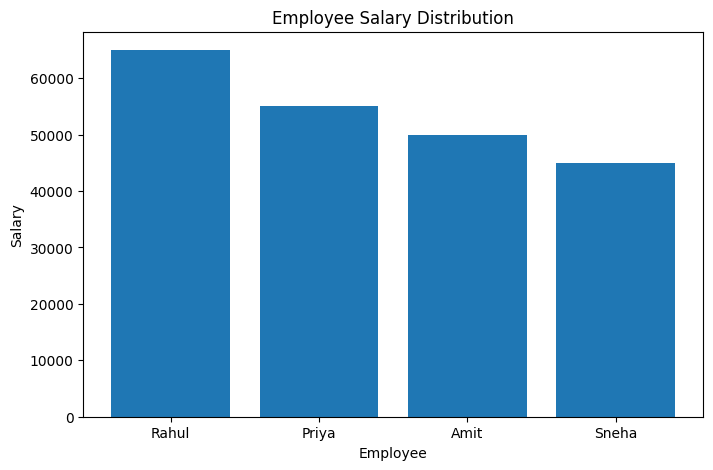

In [ ]:
import matplotlib.pyplot as plt

df = get_employees()

plt.figure(figsize=(8,5))
plt.bar(df["employee_name"], df["salary"])

plt.xlabel("Employee")
plt.ylabel("Salary")
plt.title("Employee Salary Distribution")

plt.show()

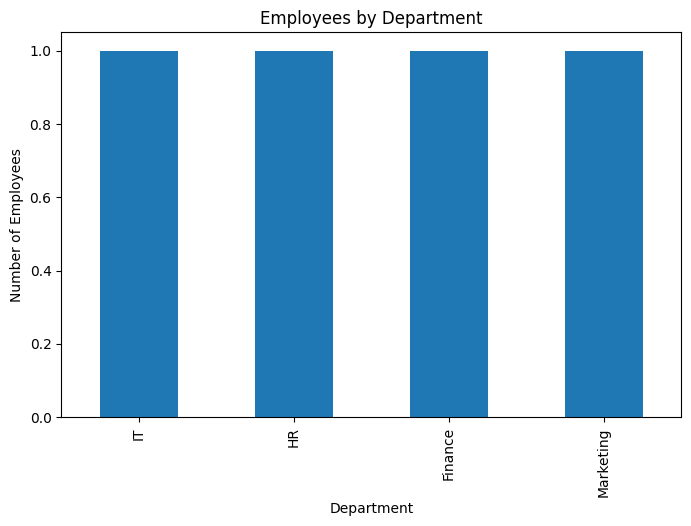

In [ ]:
department_count = df["department_name"].value_counts()

plt.figure(figsize=(8,5))
department_count.plot(kind="bar")

plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.title("Employees by Department")

plt.show()

## Result

The Python-based employee management system was successfully implemented using PostgreSQL. CRUD operations were performed successfully and employee data was visualized using Pandas and Matplotlib.

## Conclusion

PostgreSQL was successfully integrated with Python to manage relational employee data. CRUD operations and data visualization were performed successfully using Python, Pandas, and Matplotlib.